# Maquinas de soporte vectorial

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons, make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [52]:
def graficar_modelo(
    modelo,
    X,
    y,
    titulo="Frontera de decisión"
):
    
    # Crear figura
    plt.figure(figsize=(8, 6))
    
    # Límites de la región que vamos a visualizar
    x_min = X[:, 0].min() - 0.8
    x_max = X[:, 0].max() + 0.8
    
    y_min = X[:, 1].min() - 0.8
    y_max = X[:, 1].max() + 0.8
    
    # Crear una malla de puntos
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 400),
        np.linspace(y_min, y_max, 400)
    )
    
    # Convertir la malla en pares (X1, X2)
    grid = np.c_[
        xx.ravel(),
        yy.ravel()
    ]
    
    # Predecir la clase de cada punto de la malla
    Z_pred = modelo.predict(grid)
    
    # Regresar al formato de la malla
    Z_pred = Z_pred.reshape(xx.shape)
    
    # Colorear las regiones según la clase predicha
    plt.contourf(
        xx,
        yy,
        Z_pred,
        alpha=0.15
    )

    # Evaluar la función de decisión en toda la malla
    Z_decision = modelo.decision_function(grid)
    
    # Esta función está pensada para clasificación binaria
    Z_decision = Z_decision.reshape(xx.shape)
    
    # Sólo incluimos niveles que realmente estén dentro
    # del rango de la función de decisión
    niveles = [
        nivel
        for nivel in [-1, 0, 1]
        if Z_decision.min() <= nivel <= Z_decision.max()
    ]
    
    # Dibujamos los niveles únicamente si existen
    if len(niveles) > 0:
        
        estilos = [
            "-" if nivel == 0 else "--"
            for nivel in niveles
        ]
        
        plt.contour(
            xx,
            yy,
            Z_decision,
            levels=niveles,
            linestyles=estilos
        )
    
    for clase in np.unique(y):
        
        plt.scatter(
            X[y == clase, 0],
            X[y == clase, 1],
            label=f"Clase {clase}",
            s=60
        )
    

    plt.xlabel("$X_1$")
    plt.ylabel("$X_2$")
    plt.title(titulo)
    plt.legend()
    plt.show()

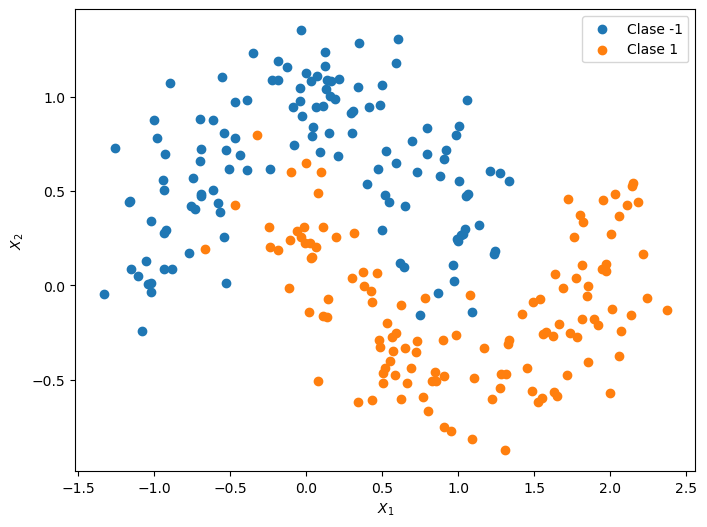

In [53]:
X, y = make_moons(n_samples = 250, noise = 0.2, random_state = 42)
y = np.where(y==0, -1,1)
plt.figure(figsize = (8,6))

for clase in np.unique(y):
    plt.scatter(
        X[y==clase, 0],
        X[y==clase, 1],
        label =f"Clase {clase}"
    )
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.legend()
plt.show()

In [54]:
X_train, X_test, y_train, y_test = train_test_split(
    X,y, test_size = 0.3, random_state = 42, stratify = y
)

modelo_lineal = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel = "linear", C =1))
    ]
)

modelo_lineal.fit(X_train,y_train)


scaler_ajustado = modelo_lineal.named_steps["scaler"]
media = scaler_ajustado.mean_
desviacion = scaler_ajustado.scale_
pred_ajustado = modelo_lineal.named_steps["svc"]
coeficientes =pred_ajustado.coef_[0]
intercepto = pred_ajustado.intercept_[0]

def prediction1(X):
    scalex0 = (np.array(X[:,0])+media[0])/desviacion[0]
    scalex1 = (np.array(X[:,1])+media[1])/desviacion[1]
    pred = intercepto + scalex0*coeficientes[0] + scalex1*coeficientes[1]
    res = []
    for i in range(0,len(pred)):
        if pred[i]<0:
            res.append(-1)
        else:
            res.append(1)
    return res
    
pred2 = prediction1(X_test)   


In [55]:
X_train[:3]
scaler_ajustado.transform(X_train[:3])


array([[ 1.49761141, -0.6328799 ],
       [ 0.52930545, -0.47281312],
       [ 0.86902049, -1.4281367 ]])

In [56]:
prediccion_pipeline=modelo_lineal.predict(X_test)

print(pred2==prediccion_pipeline)
print(accuracy_score(prediccion_pipeline, y_test))

[ True  True  True  True  True  True  True  True  True  True  True False
  True False False  True  True  True False  True  True  True  True  True
  True False  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True False  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True False
 False  True  True]
0.8666666666666667


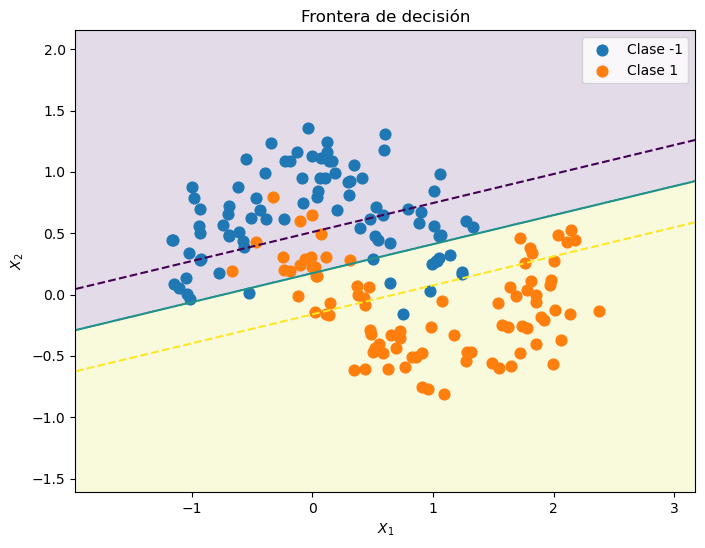

In [57]:
graficar_modelo(modelo_lineal, X_train, y_train)

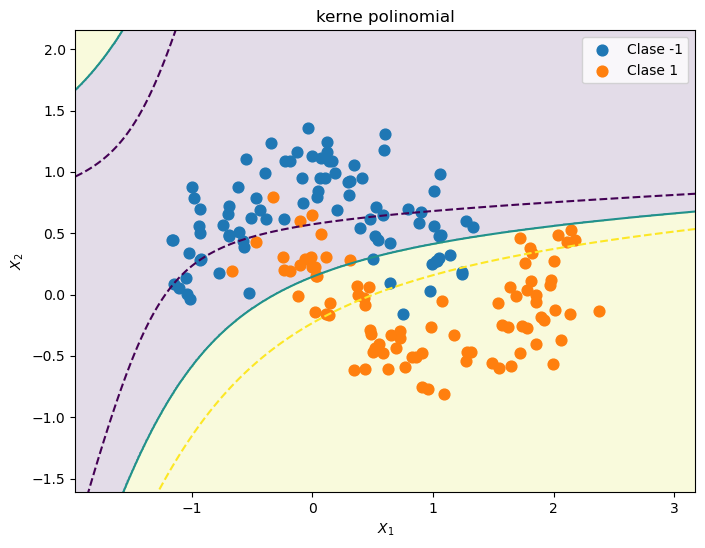

In [65]:
modelo_poly2 = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svc",
        SVC(
            kernel="poly",
            degree=2,
            C=1,
            gamma="scale",
            coef0=1
        )
    )
])

modelo_poly2.fit(X_train,y_train)
graficar_modelo(modelo_poly2, X_train,y_train, titulo = "kerne polinomial")